# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: C:\Users\victo\ml-course\data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [2]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

**Cómo se resuelve y por qué:** reshape reorganiza los 140 valores sin cambiar su orden: 28 días por 5 productos. Los índices empiezan en cero.

In [3]:
ventas = ventas_planas.reshape(28, 5)
print('Forma:', ventas.shape, 'Dimensiones:', ventas.ndim)
print('Elementos:', ventas.size, 'Tipo:', ventas.dtype)
print('Cafés del primer día:', ventas[0, 0])
assert ventas[0, 0] == ventas_planas[0]

Forma: (28, 5) Dimensiones: 2
Elementos: 140 Tipo: int64
Cafés del primer día: 35


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

**Cómo se resuelve y por qué:** Antes de la coma elegimos filas y después columnas. El extremo derecho de un slice no se incluye; -7 selecciona desde la séptima fila contando desde el final.

In [4]:
print('Primer día:', ventas[0, :])
print('Latte:', ventas[:, 1])
ultima_semana = ventas[-7:, :]
print('Última semana:', ultima_semana, 'Forma:', ultima_semana.shape)
print('Croissant y sándwich, primera semana:', ventas[:7, -2:])
assert ultima_semana.shape == (7, 5)

Primer día: [35 28  7 16 13]
Latte: [28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]
Última semana: [[22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]
 [49 45 18 27  9]] Forma: (7, 5)
Croissant y sándwich, primera semana: [[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]
 [29 12]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

**Cómo se resuelve y por qué:** El broadcasting aplica los cinco precios a cada fila. axis=1 suma productos y conserva un resultado por día; ingresos son ventas monetarias, no beneficio porque faltan los costos.

In [5]:
ingresos = ventas * precios
ingreso_diario = ingresos.sum(axis=1)
print('Ingreso mensual:', round(ingresos.sum(), 2))
print('Media, máximo y mínimo diarios:', ingreso_diario.mean(), ingreso_diario.max(), ingreso_diario.min())

Ingreso mensual: 6342.5
Media, máximo y mínimo diarios: 226.5178571428572 337.29999999999995 165.89999999999998


### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

**Cómo se resuelve y por qué:** Una máscara es un array de True y False. Filtra los días que cumplen la condición y su suma cuenta cuántos la cumplen.

In [6]:
dias = np.arange(1, 29)
mascara = ingreso_diario > ingreso_diario.mean()
print('Días buenos:', dias[mascara])
print('Cantidad:', mascara.sum())
etiquetas = np.where(mascara, 'bueno', 'flojo')
print(etiquetas)
print('Restos:', dias[mascara] % 7)

Días buenos: [ 1  6  7 13 14 19 20 21 23 27 28]
Cantidad: 11
['bueno' 'flojo' 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo'
 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo' 'flojo' 'flojo'
 'bueno' 'bueno' 'bueno' 'flojo' 'bueno' 'flojo' 'flojo' 'flojo' 'bueno'
 'bueno']
Restos: [1 6 0 6 0 5 6 0 2 6 0]


**Respuesta explicada:**

Hay 11 días buenos: [1, 6, 7, 13, 14, 19, 20, 21, 23, 27, 28]. Sus restos son [1, 6, 0, 6, 0, 5, 6, 0, 2, 6, 0]. Incluyen los ocho días de fin de semana, pero también los días 1, 19 y 23 (lunes, viernes y martes). Predomina el fin de semana, sin ser una regla absoluta: el generador asignó un 50% más de ventas esperadas a esos días, pero las ventas fluctúan al azar.

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

**Cómo se resuelve y por qué:** Cada fila ahora es una semana. Comparamos medias por día, porque hay cinco días laborables y solo dos de fin de semana; comparar sus totales sería engañoso.

In [7]:
por_semana = ingreso_diario.reshape(4, 7)
nombres_dias = np.array(['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo'])
print('Ingresos por semana:', por_semana.sum(axis=1))
promedios_dia = por_semana.mean(axis=0)
print(pd.Series(promedios_dia, index=nombres_dias))
print('Mayor ingreso medio:', nombres_dias[promedios_dia.argmax()])
media_fin = por_semana[:, 5:].mean()
media_laborable = por_semana[:, :5].mean()
print('Fin de semana:', media_fin, 'Entre semana:', media_laborable)
print('Razón:', media_fin / media_laborable)

Ingresos por semana: [1577.8 1604.5 1575.6 1584.6]
lunes        191.625
martes       195.200
miércoles    191.175
jueves       195.900
viernes      200.750
sábado       302.950
domingo      308.025
dtype: float64
Mayor ingreso medio: domingo
Fin de semana: 305.4875 Entre semana: 194.93
Razón: 1.5671651362027395


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

**Cómo se resuelve y por qué:** axis=0 suma los días y deja un total por producto. Dividimos cada total entre el total general y multiplicamos por cien para obtener porcentajes.

In [8]:
ingresos_producto = ingresos.sum(axis=0)
unidades_producto = ventas.sum(axis=0)
print(pd.DataFrame({'producto': productos, 'ingreso': ingresos_producto,
                    'porcentaje': (100 * ingresos_producto / ingresos_producto.sum()).round(1),
                    'unidades': unidades_producto}))
print('Más dinero:', productos[ingresos_producto.argmax()])
print('Más unidades:', productos[unidades_producto.argmax()])

    producto  ingreso  porcentaje  unidades
0       café   1483.5        23.4       989
1      latte   2018.8        31.8       721
2         té    457.2         7.2       381
3  croissant   1114.0        17.6       557
4   sándwich   1269.0        20.0       282
Más dinero: latte
Más unidades: café


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

**Respuesta explicada:**

El café vende 989 unidades, pero el latte genera 2018.80 dólares con 721 unidades porque su precio es mayor (2.8 frente a 1.5). Mantendría existencias de ambos y revisaría costos y margen antes de decidir promociones: facturar más no implica ganar más.

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

**Cómo se resuelve y por qué:** read_csv carga una tabla. head enseña ejemplos, info resume tipos y nulos, y describe muestra la distribución numérica.

In [9]:
propinas = pd.read_csv(DATA_DIR / 'tips.csv')
print('Forma:', propinas.shape)
display(propinas.head())
propinas.info()
display(propinas.describe())

Forma: (244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.90

**Cómo se resuelve y por qué:** value_counts cuenta observaciones por categoría; isna permite comprobar datos faltantes sin adivinarlos por las primeras filas.

In [10]:
print(propinas['day'].value_counts())
print(propinas['time'].value_counts())
print('Nulos:', propinas.isna().sum())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
time
Dinner    176
Lunch      68
Name: count, dtype: int64
Nulos: total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

**Respuesta explicada:**

Hay 244 mesas y 0 valores faltantes. La cuenta máxima fue 50.81 dólares y la mesa más grande tenía 6 personas.

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

**Cómo se resuelve y por qué:** rename cambia nombres de columnas; map cambia sus valores según un diccionario. Un valor no contemplado por map se convertiría en nulo.

In [11]:
propinas = propinas.rename(columns={'total_bill': 'cuenta', 'tip': 'propina', 'sex': 'sexo',
    'smoker': 'fumador', 'day': 'dia', 'time': 'momento', 'size': 'personas'})
traducciones = {
    'dia': {'Thur': 'Jueves', 'Fri': 'Viernes', 'Sat': 'Sábado', 'Sun': 'Domingo'},
    'momento': {'Lunch': 'Comida', 'Dinner': 'Cena'},
    'sexo': {'Female': 'Mujer', 'Male': 'Hombre'},
    'fumador': {'Yes': 'sí', 'No': 'no'}}
for columna, diccionario in traducciones.items():
    propinas[columna] = propinas[columna].map(diccionario)
display(propinas.head())

   cuenta  propina    sexo fumador      dia momento  personas
0   16.99     1.01   Mujer      no  Domingo    Cena         2
1   10.34     1.66  Hombre      no  Domingo    Cena         3
2   21.01     3.50  Hombre      no  Domingo    Cena         3
3   23.68     3.31  Hombre      no  Domingo    Cena         2
4   24.59     3.61   Mujer      no  Domingo    Cena         4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

**Cómo se resuelve y por qué:** El porcentaje hace comparables cuentas distintas. pd.cut incluye el límite superior: 2 queda en el primer intervalo y 4 en el segundo.

In [12]:
propinas['pct_propina'] = 100 * propinas['propina'] / propinas['cuenta']
propinas['cuenta_por_persona'] = propinas['cuenta'] / propinas['personas']
propinas['tamaño_mesa'] = pd.cut(propinas['personas'], bins=[0, 2, 4, 6], labels=['1-2', '3-4', '5-6'])
propinas['generosa'] = np.where(propinas['pct_propina'] >= 20, 'sí', 'no')
display(propinas.head())

   cuenta  propina    sexo  ... cuenta_por_persona tamaño_mesa generosa
0   16.99     1.01   Mujer  ...           8.495000         1-2       no
1   10.34     1.66  Hombre  ...           3.446667         3-4       no
2   21.01     3.50  Hombre  ...           7.003333         3-4       no
3   23.68     3.31  Hombre  ...          11.840000         1-2       no
4   24.59     3.61   Mujer  ...           6.147500         3-4       no

[5 rows x 11 columns]


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

**Cómo se resuelve y por qué:** Cada condición necesita paréntesis al combinarla con &. La media de una máscara es la proporción de True. Aquí entre 10 y 20 incluye ambos extremos.

In [13]:
generosas = propinas['generosa'] == 'sí'
print('Generosas:', generosas.sum(), 'Proporción:', generosas.mean())
cenas_grandes = propinas[(propinas['momento'] == 'Cena') & propinas['dia'].isin(['Sábado', 'Domingo']) & (propinas['personas'] >= 4)]
print('Cenas grandes de fin de semana:', len(cenas_grandes), 'Porcentaje medio:', cenas_grandes['pct_propina'].mean())
display(propinas.sort_values('pct_propina', ascending=False)[['cuenta', 'propina', 'pct_propina', 'personas', 'dia']].head(5))
fumadores_10_20 = propinas.query("fumador == 'sí' and 10 <= cuenta <= 20")
print('Mesas fumadoras entre 10 y 20:', len(fumadores_10_20))

Generosas: 39 Proporción: 0.1598360655737705
Cenas grandes de fin de semana: 36 Porcentaje medio: 14.568543736491607
     cuenta  propina  pct_propina  personas      dia
172    7.25     5.15    71.034483         2  Domingo
178    9.60     4.00    41.666667         2  Domingo
67     3.07     1.00    32.573290         1   Sábado
232   11.61     3.39    29.198966         2   Sábado
183   23.17     6.50    28.053517         4  Domingo
Mesas fumadoras entre 10 y 20: 46


### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

**Cómo se resuelve y por qué:** Agrupamos por día y calculamos tamaño de muestra, media y mediana. La mediana suele resistir mejor valores extremos.

In [14]:
display(propinas.groupby('dia')['pct_propina'].agg(['count', 'mean', 'median']).round(1))

         count  mean  median
dia                         
Domingo     76  16.7    16.1
Jueves      62  16.1    15.4
Sábado      87  15.3    15.2
Viernes     19  17.0    15.6


**Cómo se resuelve y por qué:** La agregación con nombres permite resumir diferentes columnas y nombrar claramente cada resultado.

In [15]:
resumen_momento = propinas.groupby('momento').agg(n_mesas=('propina', 'size'),
    cuenta_media=('cuenta', 'mean'), propina_media=('propina', 'mean'), pct_medio=('pct_propina', 'mean'))
display(resumen_momento.round(1))

         n_mesas  cuenta_media  propina_media  pct_medio
momento                                                 
Cena         176          20.8            3.1       16.0
Comida        68          17.2            2.7       16.4


**Cómo se resuelve y por qué:** Contar mesas junto con la media evita dar la misma confianza a grupos muy pequeños y grandes.

In [16]:
resumen_personas = propinas.groupby('personas').agg(n_mesas=('propina', 'size'), pct_medio=('pct_propina', 'mean'))
display(resumen_personas.round(1))

          n_mesas  pct_medio
personas                    
1               4       21.7
2             156       16.6
3              38       15.2
4              37       14.6
5               5       14.1
6               4       15.6


**Cómo se resuelve y por qué:** La tabla dinámica cruza dos categorías y resume el porcentaje en cada combinación. Es descriptiva, no demuestra causalidad.

In [17]:
display(pd.pivot_table(propinas, values='pct_propina', index='sexo', columns='fumador', aggfunc='mean').round(1))

fumador    no    sí
sexo               
Hombre   16.1  15.3
Mujer    15.7  18.2


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

**Respuesta explicada:**

El porcentaje medio de mesas de 2 personas es 16.57% y el de 4 es 14.59%. No hay un descenso perfectamente regular. Para 1, 5 y 6 personas hay solo [4, 5, 4] mesas respectivamente; unas pocas observaciones pueden cambiar mucho sus medias.

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

**Cómo se resuelve y por qué:** crosstab cuenta combinaciones. Permite detectar que el momento del servicio y el día no están distribuidos de manera independiente.

In [18]:
tabla_momento = pd.crosstab(propinas['dia'], propinas['momento'])
display(tabla_momento)

momento  Cena  Comida
dia                  
Domingo    76       0
Jueves      1      61
Sábado     87       0
Viernes    12       7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

**Respuesta explicada:**

También comparamos días diferentes: el jueves tiene 61 comidas y 1 cena; sábado y domingo solo tienen cenas (87 y 76). El viernes tiene 7 comidas y 12 cenas. Por ello no podemos atribuir una diferencia únicamente a comer o cenar.

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

**Cómo se resuelve y por qué:** Unimos por dia. many_to_one comprueba que la tabla auxiliar tiene una sola fila por día para evitar duplicar mesas accidentalmente.

In [19]:
info_dias = pd.DataFrame({'dia': ['Jueves', 'Viernes', 'Sábado', 'Domingo'],
    'orden': [4, 5, 6, 7], 'fin_de_semana': [False, False, True, True]})
n_antes = len(propinas)
propinas = propinas.merge(info_dias, on='dia', how='left', validate='many_to_one')
assert len(propinas) == n_antes
display(propinas.groupby('fin_de_semana')[['cuenta', 'pct_propina']].mean())
display(propinas.groupby(['orden', 'dia'])['cuenta'].sum())

                  cuenta  pct_propina
fin_de_semana                        
False          17.558148    16.330169
True           20.893006    15.956069
orden  dia    
4      Jueves     1096.33
5      Viernes     325.88
6      Sábado     1778.40
7      Domingo    1627.16
Name: cuenta, dtype: float64


### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

**Cómo se resuelve y por qué:** to_numpy elimina las etiquetas. Debemos recordar el orden de las columnas y usar índices numéricos para calcular y filtrar.

In [20]:
X = propinas[['cuenta', 'propina', 'personas']].to_numpy()
pct_numpy = 100 * X[:, 1] / X[:, 0]
print('Forma:', X.shape, 'Media:', pct_numpy.mean())
assert np.isclose(pct_numpy.mean(), propinas['pct_propina'].mean())
print('Mesas de 2 con más de 4 dólares:', np.sum((X[:, 2] == 2) & (X[:, 1] > 4)))

Forma: (244, 3) Media: 16.08025817225047
Mesas de 2 con más de 4 dólares: 13


### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

**Respuesta explicada:**

1. 39 de 244 mesas (15.98%) dejaron al menos 20%.
2. La propina media en comidas fue 2.73 dólares y en cenas 3.10.
3. Las mesas de dos personas dejaron 16.57% en promedio, frente a 14.59% en las de cuatro.
Limitación: es una muestra observacional de un camarero; día y momento se mezclan y no hay asignación aleatoria. No garantiza que cambiar de turno o atender grupos concretos cause mejores propinas.

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

**Cómo se resuelve y por qué:** Una línea conserva el orden temporal y hace visibles los cambios entre días.

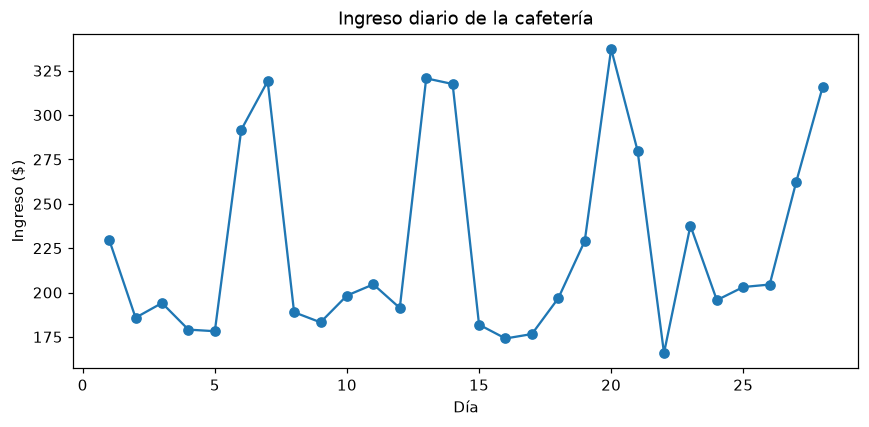

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(dias, ingreso_diario, marker='o')
plt.title('Ingreso diario de la cafetería')
plt.xlabel('Día')
plt.ylabel('Ingreso ($)')
plt.tight_layout()
plt.show()

**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

**Cómo se resuelve y por qué:** Las barras comparan magnitudes de categorías distintas.

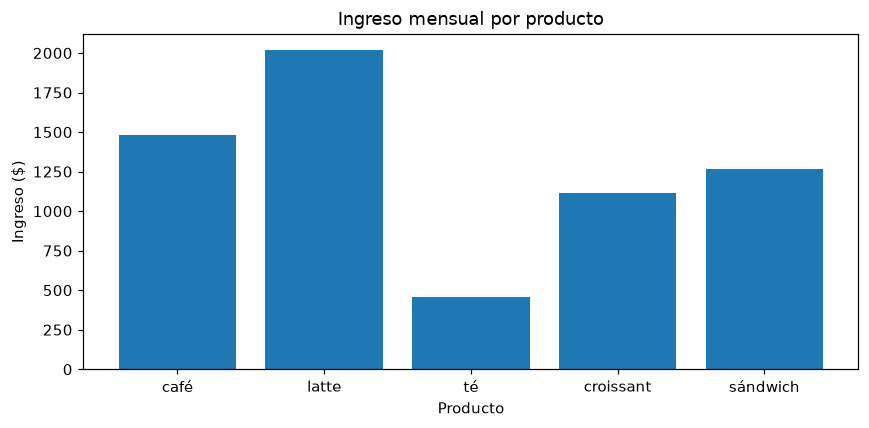

In [22]:
plt.figure(figsize=(8, 4))
plt.bar(productos, ingresos_producto)
plt.title('Ingreso mensual por producto')
plt.xlabel('Producto')
plt.ylabel('Ingreso ($)')
plt.tight_layout()
plt.show()

**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

**Cómo se resuelve y por qué:** Una serie por producto permite comparar su evolución; la leyenda identifica cada línea.

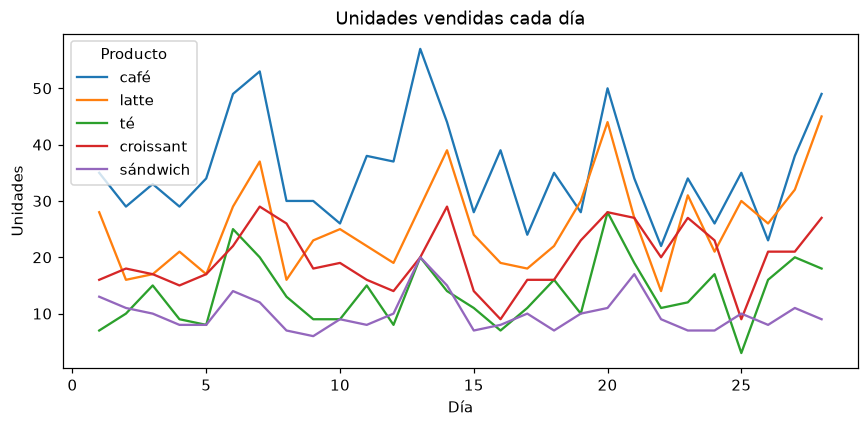

In [23]:
plt.figure(figsize=(8, 4))
for i, producto in enumerate(productos):
    plt.plot(dias, ventas[:, i], label=producto)
plt.legend(title='Producto')
plt.title('Unidades vendidas cada día')
plt.xlabel('Día')
plt.ylabel('Unidades')
plt.tight_layout()
plt.show()

**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

**Cómo se resuelve y por qué:** El mapa de calor representa cada celda de la matriz mediante color; la barra indica su escala.

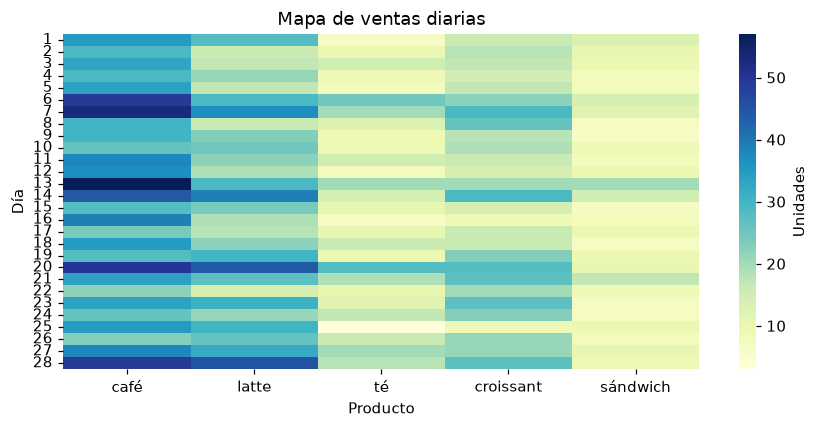

In [24]:
plt.figure(figsize=(8, 4))
sns.heatmap(ventas, xticklabels=productos, yticklabels=dias, cmap='YlGnBu', cbar_kws={'label': 'Unidades'})
plt.title('Mapa de ventas diarias')
plt.xlabel('Producto')
plt.ylabel('Día')
plt.tight_layout()
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

**Cómo se resuelve y por qué:** El histograma agrupa valores numéricos en intervalos para ver frecuencia y asimetría.

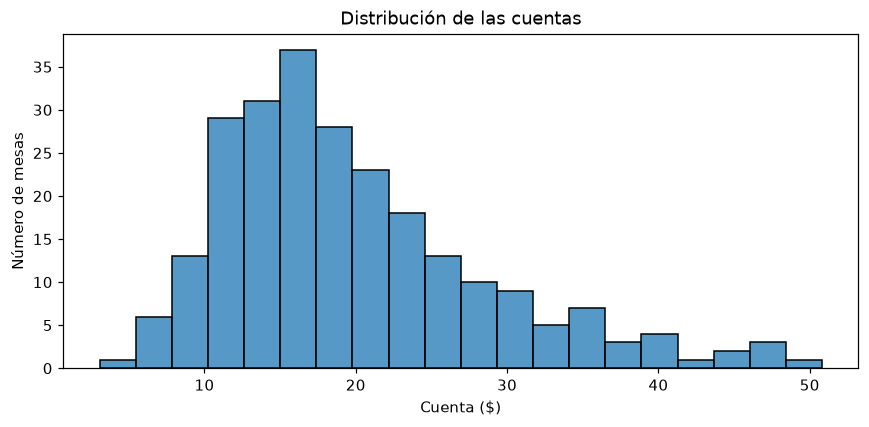

In [25]:
plt.figure(figsize=(8, 4))
sns.histplot(data=propinas, x='cuenta', bins=20)
plt.title('Distribución de las cuentas')
plt.xlabel('Cuenta ($)')
plt.ylabel('Número de mesas')
plt.tight_layout()
plt.show()

**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

**Cómo se resuelve y por qué:** Cada punto es una mesa; la dispersión permite estudiar la asociación de dos variables numéricas.

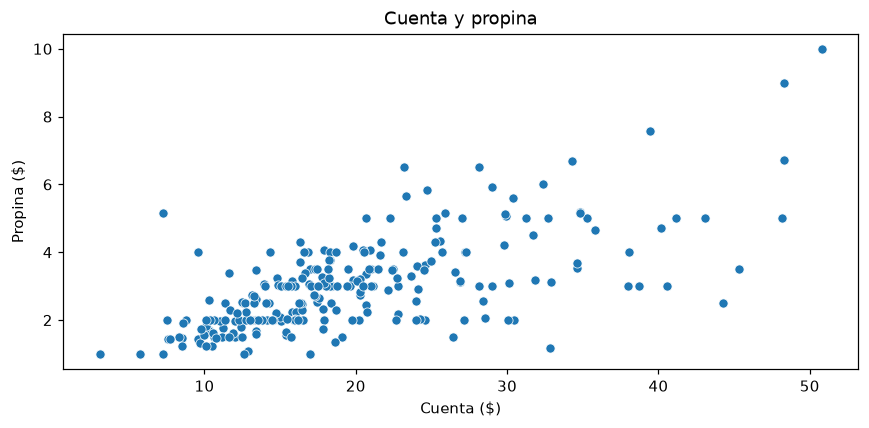

In [26]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=propinas, x='cuenta', y='propina')
plt.title('Cuenta y propina')
plt.xlabel('Cuenta ($)')
plt.ylabel('Propina ($)')
plt.tight_layout()
plt.show()

**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

**Cómo se resuelve y por qué:** El color añade una categoría sin perder la relación numérica entre cuenta y propina.

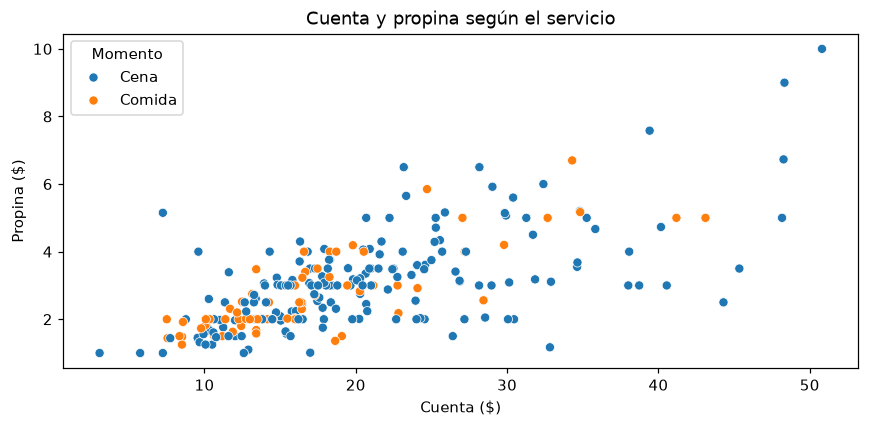

In [27]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=propinas, x='cuenta', y='propina', hue='momento')
plt.legend(title='Momento')
plt.title('Cuenta y propina según el servicio')
plt.xlabel('Cuenta ($)')
plt.ylabel('Propina ($)')
plt.tight_layout()
plt.show()

**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

**Cómo se resuelve y por qué:** El boxplot muestra mediana, cuartiles y posibles extremos. Un punto fuera de los bigotes no implica un error.

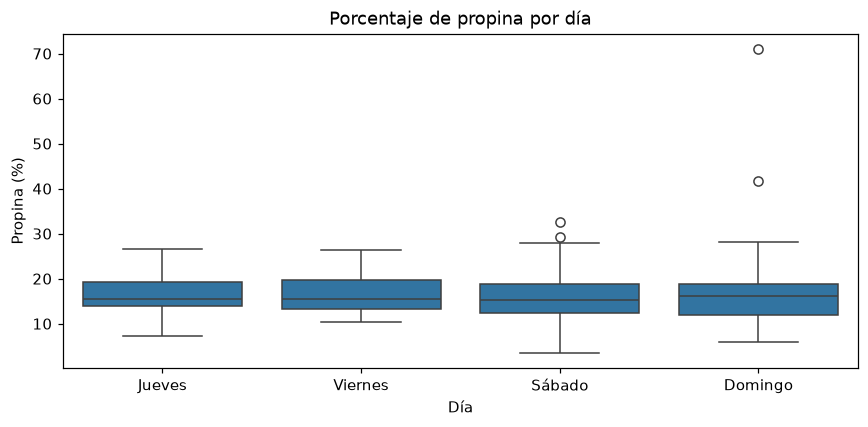

In [28]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=propinas, x='dia', y='pct_propina', order=['Jueves','Viernes','Sábado','Domingo'])
plt.title('Porcentaje de propina por día')
plt.xlabel('Día')
plt.ylabel('Propina (%)')
plt.tight_layout()
plt.show()

**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

**Cómo se resuelve y por qué:** countplot cuenta filas por categoría; no calcula medias.

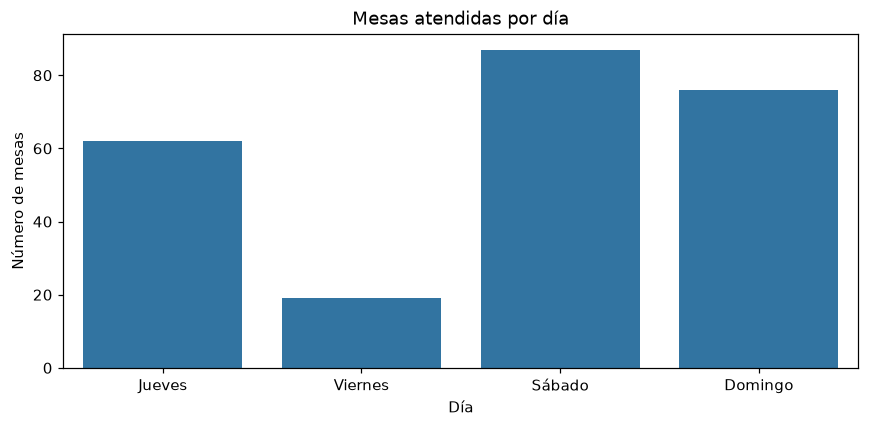

In [29]:
plt.figure(figsize=(8, 4))
sns.countplot(data=propinas, x='dia', order=['Jueves','Viernes','Sábado','Domingo'])
plt.title('Mesas atendidas por día')
plt.xlabel('Día')
plt.ylabel('Número de mesas')
plt.tight_layout()
plt.show()

**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

**Cómo se resuelve y por qué:** Las barras agrupadas comparan medias. Omitimos intervalos para mostrar exactamente el resumen solicitado; grupos pequeños son menos estables.

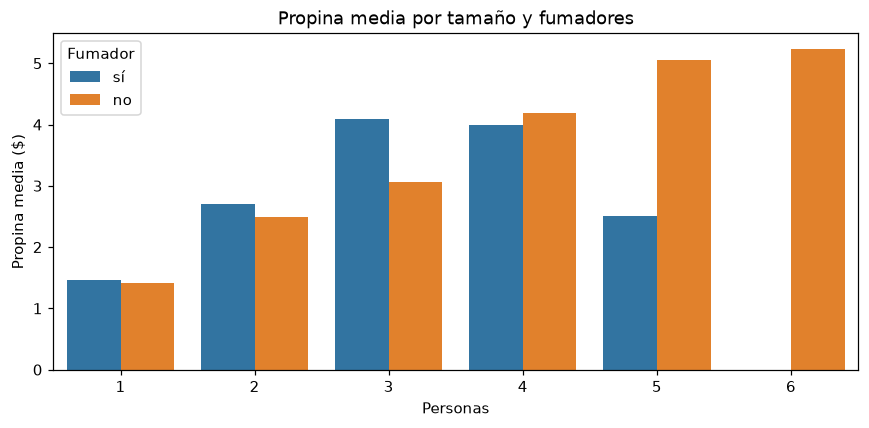

In [30]:
plt.figure(figsize=(8, 4))
sns.barplot(data=propinas, x='personas', y='propina', hue='fumador', errorbar=None)
plt.legend(title='Fumador')
plt.title('Propina media por tamaño y fumadores')
plt.xlabel('Personas')
plt.ylabel('Propina media ($)')
plt.tight_layout()
plt.show()

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

**Cómo se resuelve y por qué:** Cargamos el nuevo dataset. La gráfica excluye las masas faltantes sin rellenarlas artificialmente.

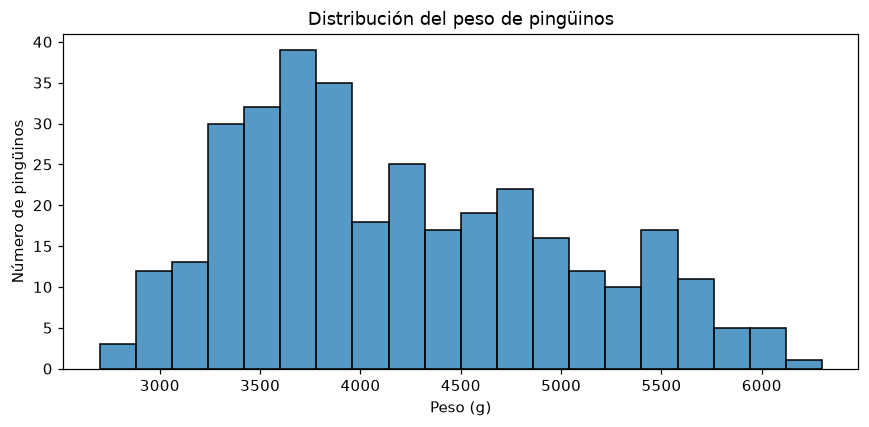

In [31]:
plt.figure(figsize=(8, 4))
pinguinos = pd.read_csv(DATA_DIR / 'penguins.csv')
sns.histplot(data=pinguinos, x='body_mass_g', bins=20)
plt.title('Distribución del peso de pingüinos')
plt.xlabel('Peso (g)')
plt.ylabel('Número de pingüinos')
plt.tight_layout()
plt.show()

**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

**Cómo se resuelve y por qué:** Normalizar cada especie por separado permite comparar formas aunque las especies tengan distintos tamaños de muestra.

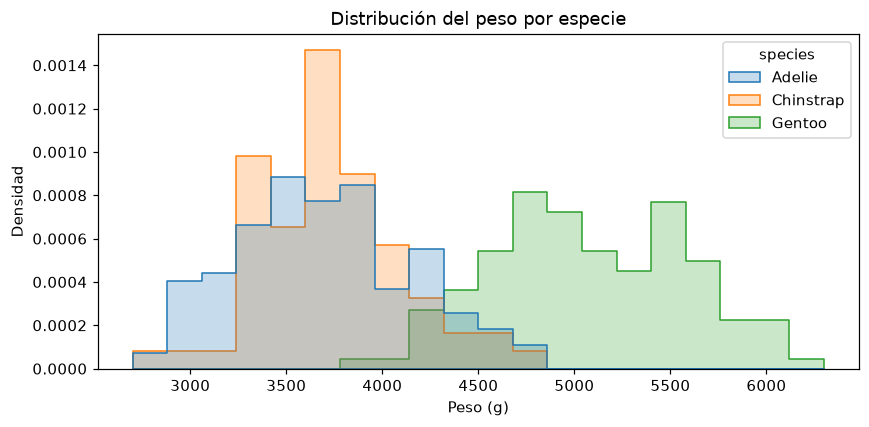

In [32]:
plt.figure(figsize=(8, 4))
sns.histplot(data=pinguinos, x='body_mass_g', hue='species', bins=20, element='step', stat='density', common_norm=False)
plt.title('Distribución del peso por especie')
plt.xlabel('Peso (g)')
plt.ylabel('Densidad')
plt.tight_layout()
plt.show()

**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

**Cómo se resuelve y por qué:** Comparamos extremos dentro de cada especie para no confundir diferencias entre especies con observaciones atípicas.

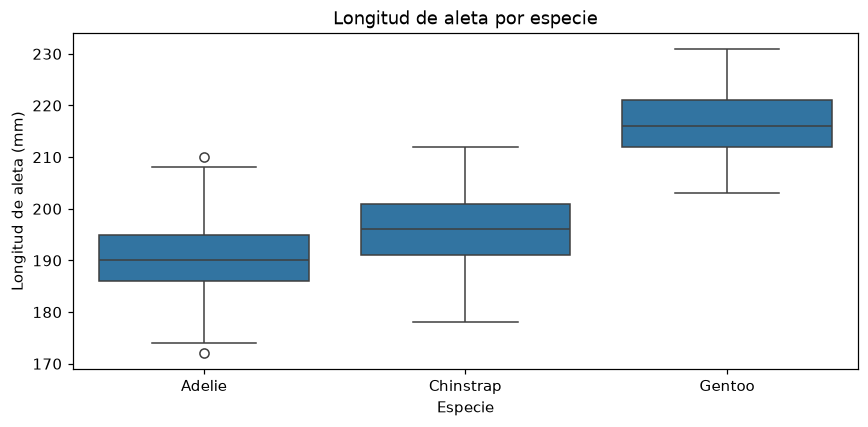

In [33]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=pinguinos, x='species', y='flipper_length_mm')
plt.title('Longitud de aleta por especie')
plt.xlabel('Especie')
plt.ylabel('Longitud de aleta (mm)')
plt.tight_layout()
plt.show()

**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

**Cómo se resuelve y por qué:** Los colores revelan agrupaciones por especie que una dispersión sin categorías podría ocultar.

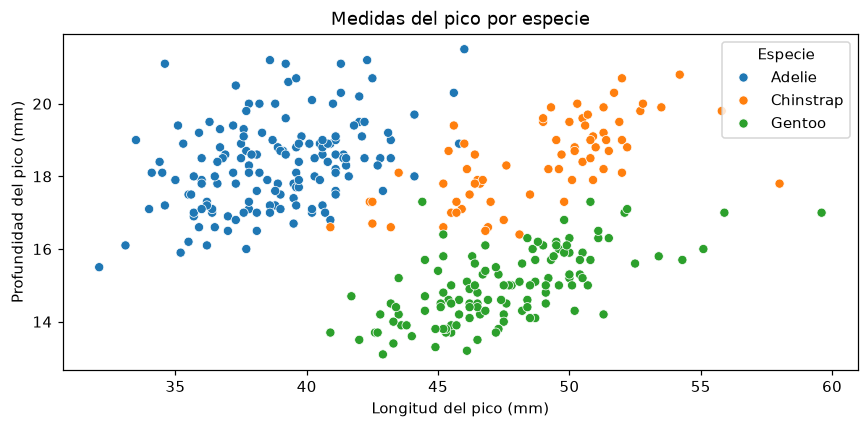

In [34]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=pinguinos, x='bill_length_mm', y='bill_depth_mm', hue='species')
plt.legend(title='Especie')
plt.title('Medidas del pico por especie')
plt.xlabel('Longitud del pico (mm)')
plt.ylabel('Profundidad del pico (mm)')
plt.tight_layout()
plt.show()

**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

**Cómo se resuelve y por qué:** subplots crea varios ejes en una figura. Dibujar cada variable por separado evita mezclar unidades y escalas.

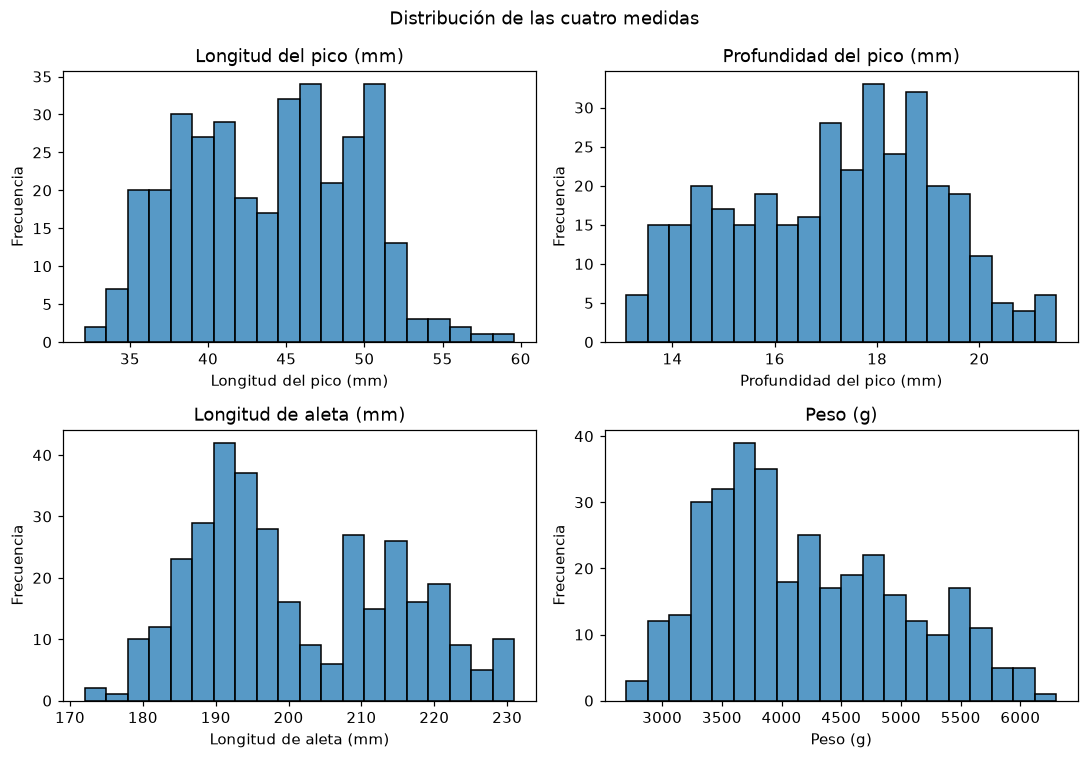

In [35]:
medidas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
etiquetas_medidas = ['Longitud del pico (mm)', 'Profundidad del pico (mm)', 'Longitud de aleta (mm)', 'Peso (g)']
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, columna, etiqueta in zip(axes.flat, medidas, etiquetas_medidas):
    sns.histplot(data=pinguinos, x=columna, bins=20, ax=ax)
    ax.set(title=etiqueta, xlabel=etiqueta, ylabel='Frecuencia')
fig.suptitle('Distribución de las cuatro medidas')
plt.tight_layout()
plt.show()

**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

**Cómo se resuelve y por qué:** La correlación de Pearson resume asociación lineal de -1 a 1. Puede estar influida por la mezcla de especies y no demuestra causalidad.

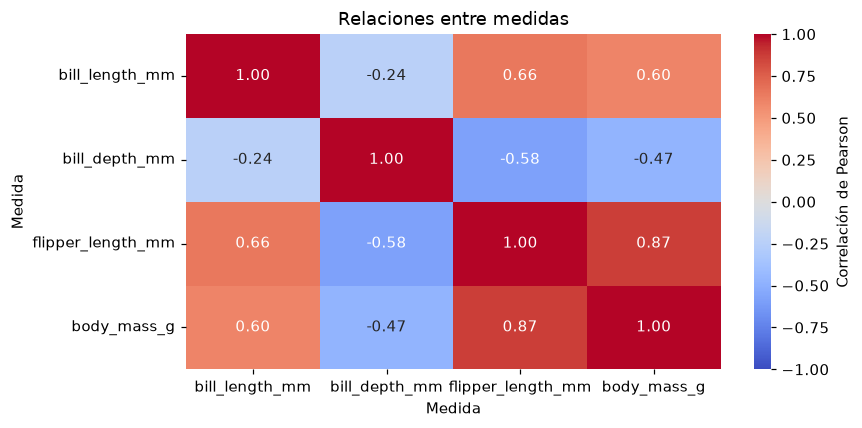

In [36]:
plt.figure(figsize=(8, 4))
correlaciones = pinguinos[medidas].corr()
sns.heatmap(correlaciones, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', cbar_kws={'label': 'Correlación de Pearson'})
plt.title('Relaciones entre medidas')
plt.xlabel('Medida')
plt.ylabel('Medida')
plt.tight_layout()
plt.show()

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

**Cómo se resuelve y por qué:** Agrupamos por especie y sexo y comparamos el peso medio. Los registros sin sexo no entran en esas categorías.

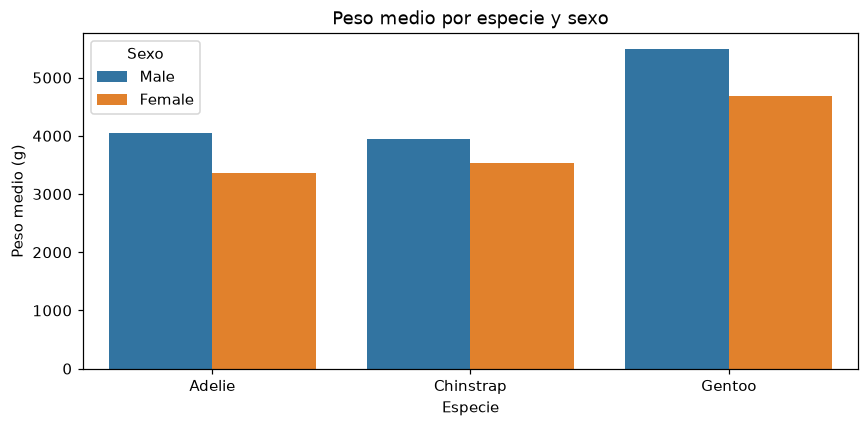

In [37]:
plt.figure(figsize=(8, 4))
sns.barplot(data=pinguinos, x='species', y='body_mass_g', hue='sex', errorbar=None)
plt.legend(title='Sexo')
plt.title('Peso medio por especie y sexo')
plt.xlabel('Especie')
plt.ylabel('Peso medio (g)')
plt.tight_layout()
plt.show()